<a href="https://colab.research.google.com/github/PratikshaYadav8799/Python_Programming/blob/main/Imputations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import warnings
warnings.filterwarnings(action='ignore')

In [24]:
#Prepare dataset with missing values

import pandas as pd
import numpy as np

df=pd.DataFrame({
    'Sr.No':[1,2,3,4,5,6,7,8,9,10],
    'Name':['A','B','C','D','E','F','G','H','I','J'],
    'Department':['HR','IT','Finance',np.nan,np.nan,'HR','IT','Finance',np.nan,'IT'],
    'Salary':[50000,80000,40000,15000,42000,30000,28000,18000,14000,np.nan],
    'Years of Experience':[1,2,3,4,5,6,7,8,9,10]
})


df

,Sr.No,Name,Department,Salary,Years of Experience
0,1,A,HR,50000.0,1
1,2,B,IT,80000.0,2
2,3,C,Finance,40000.0,3
3,4,D,NaN,15000.0,4
4,5,E,NaN,42000.0,5
5,6,F,HR,30000.0,6
6,7,G,IT,28000.0,7
7,8,H,Finance,18000.0,8
8,9,I,NaN,14000.0,9
9,10,J,IT,NaN,10


In [25]:
#Prepare a dummy copy of dataset:df

df1=df.copy()
df1

,Sr.No,Name,Department,Salary,Years of Experience
0,1,A,HR,50000.0,1
1,2,B,IT,80000.0,2
2,3,C,Finance,40000.0,3
3,4,D,NaN,15000.0,4
4,5,E,NaN,42000.0,5
5,6,F,HR,30000.0,6
6,7,G,IT,28000.0,7
7,8,H,Finance,18000.0,8
8,9,I,NaN,14000.0,9
9,10,J,IT,NaN,10


In [41]:
df1

,Sr.No,Name,Department,Salary,Years of Experience
0,1,A,HR,50000.0,1
1,2,B,IT,80000.0,2
2,3,C,Finance,40000.0,3
3,4,D,IT,15000.0,4
4,5,E,IT,42000.0,5
5,6,F,HR,30000.0,6
6,7,G,IT,28000.0,7
7,8,H,Finance,18000.0,8
8,9,I,IT,14000.0,9
9,10,J,IT,1000.0,10


In [28]:
#Checking Unique Values Present in Dataset Columns
df1['Department'].unique()

array(['HR', 'IT', 'Finance', nan], dtype=object)

In [29]:
#Checking Number of Unique Values present in Dataset Columns
df1['Department'].nunique()

3

In [30]:
df1['Department'].value_counts()

,count
Department,
IT,3
HR,2
Finance,2


<Axes: ylabel='count'>

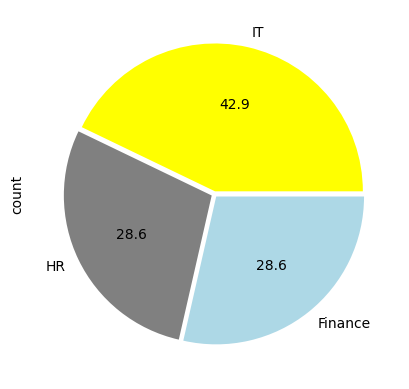

In [31]:
df1['Department'].value_counts().plot(kind='pie',
                                      autopct='%1.1f',
                                      explode=[0.02,0.02,0.02],
                                      colors=['yellow','grey','lightblue'])

In [32]:
#Imputation Strategies

'''
1.Imputation with numerical columns:
-In such cases, imputation is usually done with 'median'.
-Before imputation, please ensure the % of missing value present in dataset column.

2.Imputation with categorical columns:
-In such cases, imputation is usually done with mode.
-Before imputation, please ensure the % of missing value present in dataset column.

3.Imputation can be done in four ways:
-mean:Average value.
-median:Central value.
-mode:Most frequent occuring value.
-any arbitorary constant value.

4.In Machine Leanring Production Cycle, the Imputation can be done using the following methods:
-fillna()
-SimpleImputer() #This is the module of scikit-learn
-KnnImputer() #This is the module of scikit-learn

Note:
-10% of the missing values can be imputed.
-If dataset contains more than 10% of the missing value then better drop the column.
-If dataset contains more than 15% of the missing value then in some cases we can use bucketing technique.(Bins Technique)

'''

"\n1.Imputation with numerical columns:\n-In such cases, imputation is usually done with 'median'.\n-Before imputation, please ensure the % of missing value present in dataset column.\n\n2.Imputation with categorical columns:\n-In such cases, imputation is usually done with mode.\n-Before imputation, please ensure the % of missing value present in dataset column.\n\n3.Imputation can be done in four ways:\n-mean:Average value.\n-median:Central value.\n-mode:Most frequent occuring value.\n-any arbitorary constant value.\n\n4.In Machine Leanring Production Cycle, the Imputation can be done using the following methods:\n-fillna()\n-SimpleImputer() #This is the module of scikit-learn\n-KnnImputer() #This is the module of scikit-learn\n\nNote:\n-10% of the missing values can be imputed.\n-If dataset contains more than 10% of the missing value then better drop the column.\n-If dataset contains more than 15% of the missing value then in some cases we can use bucketing technique.(Bins Technique

In [33]:
#Imputation using fillna()

df1['Department'].fillna(df1['Department'].mode()[0],
                         inplace=True)

In [34]:
#Imputation using any arbitorary constant value
df1['Salary'].fillna(1000,
                     inplace=True)

In [35]:
df1

,Sr.No,Name,Department,Salary,Years of Experience
0,1,A,HR,50000.0,1
1,2,B,IT,80000.0,2
2,3,C,Finance,40000.0,3
3,4,D,IT,15000.0,4
4,5,E,IT,42000.0,5
5,6,F,HR,30000.0,6
6,7,G,IT,28000.0,7
7,8,H,Finance,18000.0,8
8,9,I,IT,14000.0,9
9,10,J,IT,1000.0,10


In [36]:
#Department IT
df1[df1['Department']=='IT']

,Sr.No,Name,Department,Salary,Years of Experience
1,2,B,IT,80000.0,2
3,4,D,IT,15000.0,4
4,5,E,IT,42000.0,5
6,7,G,IT,28000.0,7
8,9,I,IT,14000.0,9
9,10,J,IT,1000.0,10


In [37]:
#Department HR
df1[df1['Department']=='HR']

,Sr.No,Name,Department,Salary,Years of Experience
0,1,A,HR,50000.0,1
5,6,F,HR,30000.0,6


In [38]:
#IT Dept with salary equal and more than 10000

df1[(df1['Department']=='IT') & (df1['Salary']>=10000)]

,Sr.No,Name,Department,Salary,Years of Experience
1,2,B,IT,80000.0,2
3,4,D,IT,15000.0,4
4,5,E,IT,42000.0,5
6,7,G,IT,28000.0,7
8,9,I,IT,14000.0,9
